# Olist – Tiền xử lý dữ liệu
### ETL sang Snowflake Schema

---

| Bước | Nội dung |
|:----:|:---------|
| 1 | Import & cấu hình đường dẫn |
| 2 | Thiết lập môi trường (Google Colab) |
| 3 | Đọc dữ liệu thô |
| 4 | Khám phá & phát hiện vấn đề dữ liệu (EDA) |
| 5 | Xử lý giá trị NULL / NA |
| 6 | Kiểm tra & xử lý dữ liệu trùng lặp |
| 7 | Kiểm tra Referential Integrity (dữ liệu thô) |
| 8 | Chuẩn hóa zip code |
| 9 – 17 | Build Dimension & Fact |
| 18 | Kiểm tra Referential Integrity (schema) |
| 19 | Xuất kết quả |
| 20 | Tổng kết |

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

## 2. Thiết lập môi trường (Google Colab)

In [2]:
import zipfile

IN_COLAB = 'google.colab' in str(get_ipython()) if 'get_ipython' in dir() else False

DRIVE_FILE_ID = '1WNdO2VBOJKmR_DXMxgUfdZwpjutJ8167'   # <-- doi thanh file ID that tren Drive cua ban
LOCAL_ZIP_PATH = Path('/content/csv.zip') if IN_COLAB else Path('csv.zip')
EXTRACT_DIR = Path('/content/csv') if IN_COLAB else Path('csv')

if IN_COLAB:
    try:
        import gdown
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
        import gdown

    gdown.download(id=DRIVE_FILE_ID, output=str(LOCAL_ZIP_PATH), quiet=False)
    assert LOCAL_ZIP_PATH.exists(), f'Tai file that bai: {LOCAL_ZIP_PATH}'

    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(LOCAL_ZIP_PATH) as zf:
        zf.extractall(EXTRACT_DIR)
    print(f'Da giai nen {LOCAL_ZIP_PATH} vao {EXTRACT_DIR}')

    # csv.zip co the giai nen ra thang cac file .csv, hoac ra 1 thu muc con "csv/" ben trong
    if not any(EXTRACT_DIR.glob('*.csv')):
        subdirs = [p for p in EXTRACT_DIR.iterdir() if p.is_dir()]
        if subdirs:
            EXTRACT_DIR = subdirs[0]
            print(f'File CSV nam trong thu muc con, chuyen RAW_DIR sang {EXTRACT_DIR}')
else:
    # Chay local: tim san thu muc chua CSV trong repo, khong can tai tu Drive.
    # Notebook nam o 0.Do_an/src/ nen du lieu o 0.Do_an/data/csv/ la '../data/csv'.
    UNG_VIEN = [Path('../data/csv'), Path('data/csv'), Path('../../data/csv'),
                EXTRACT_DIR, Path('.')]
    tim_thay = next((p for p in UNG_VIEN if p.is_dir() and any(p.glob('*.csv'))), None)

    if tim_thay is not None:
        EXTRACT_DIR = tim_thay
        print(f'Chay local, dung san thu muc CSV: {EXTRACT_DIR.resolve()}')
    elif LOCAL_ZIP_PATH.exists():
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(LOCAL_ZIP_PATH) as zf:
            zf.extractall(EXTRACT_DIR)
        print(f'Da giai nen {LOCAL_ZIP_PATH} vao {EXTRACT_DIR}')
    else:
        raise FileNotFoundError(
            'Khong tim thay thu muc chua file CSV. Dat notebook canh thu muc data/csv/, '
            'hoac de csv.zip cung cap voi notebook, hoac sua truc tiep bien EXTRACT_DIR.')

RAW_DIR = EXTRACT_DIR
OUT_DIR = Path('/content/processed') if IN_COLAB else Path('processed')
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('RAW_DIR =', RAW_DIR.resolve())
print('OUT_DIR =', OUT_DIR.resolve())
print('So file .csv tim thay:', len(list(RAW_DIR.glob('*.csv'))))

Chay local, dung san thu muc CSV: D:\2_Tai_lieu\UIT\IS217\0.Do_an\data\csv
RAW_DIR = D:\2_Tai_lieu\UIT\IS217\0.Do_an\data\csv
OUT_DIR = D:\2_Tai_lieu\UIT\IS217\0.Do_an\src\processed
So file .csv tim thay: 11


### Sơ đồ Snowflake Schema

Ảnh sơ đồ (`olist_snowflake_schema.png`) được đóng gói sẵn cùng `csv.zip` (nằm cạnh các file CSV) nên sẽ có mặt ngay sau khi giải nén ở bước trên, không cần upload riêng lên Colab.

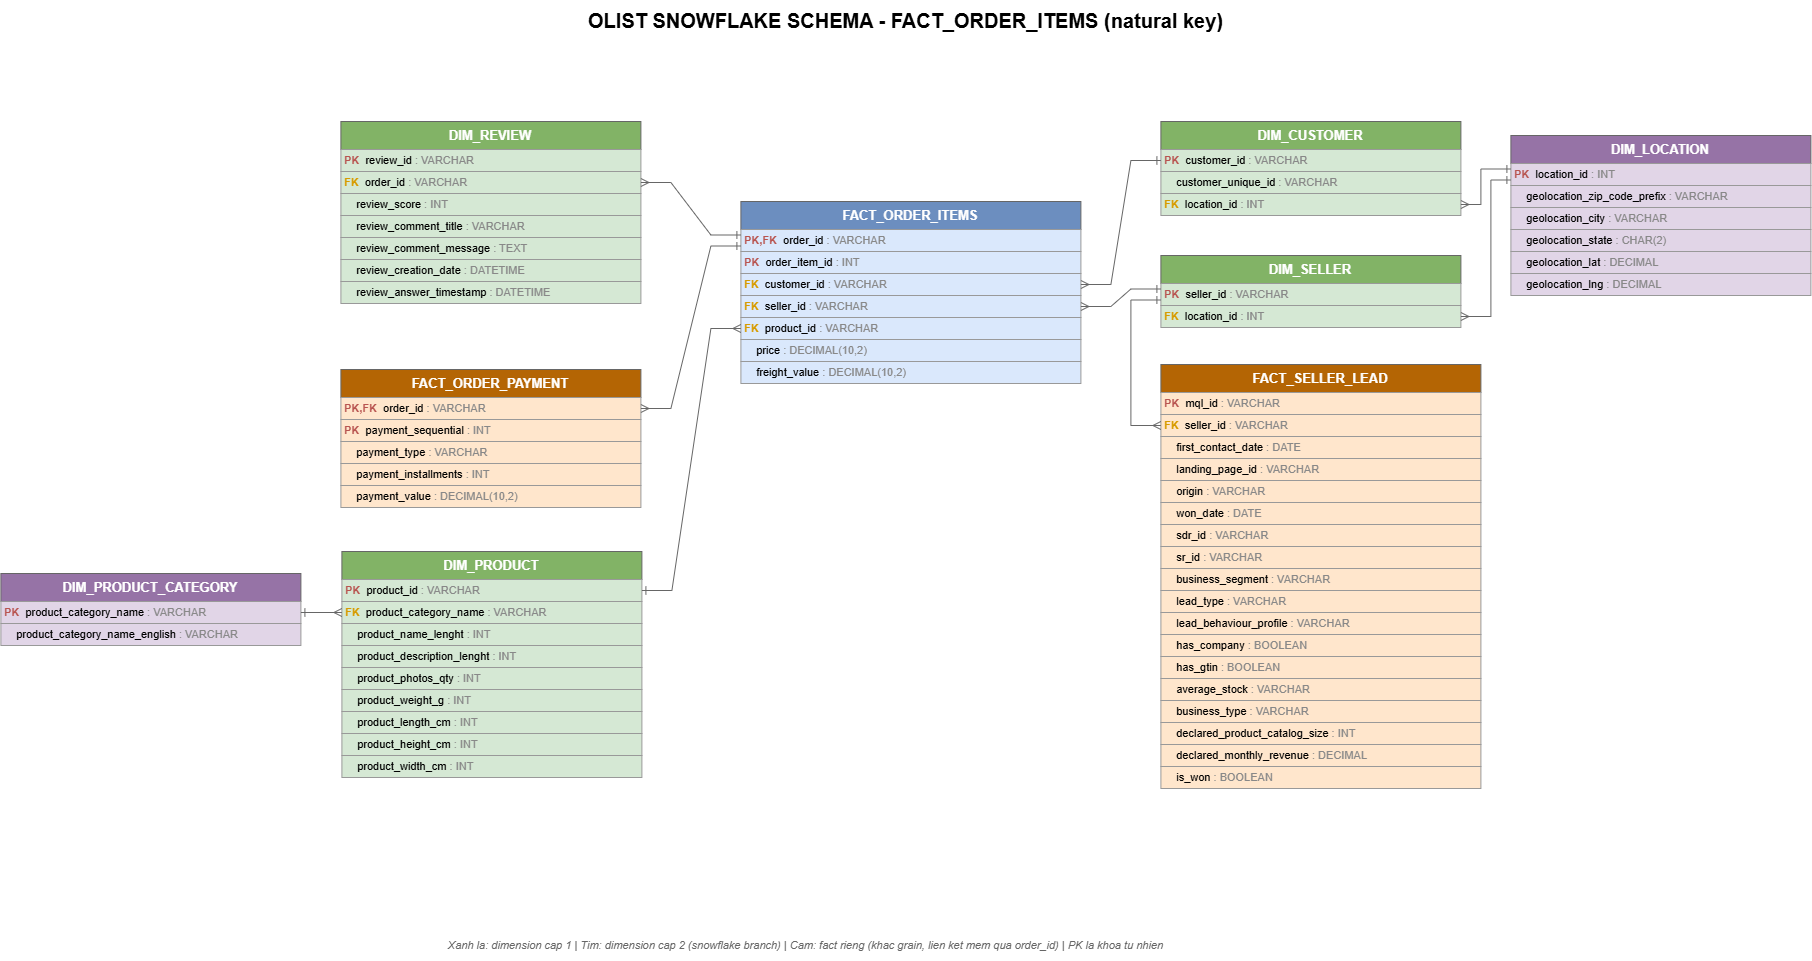

In [3]:
from IPython.display import Image, display

schema_img_path = RAW_DIR / 'olist_snowflake_schema.png'
if schema_img_path.exists():
    display(Image(filename=str(schema_img_path)))
else:
    print(f'Khong tim thay {schema_img_path} - kiem tra lai csv.zip da duoc dong goi kem anh schema chua')

## 3. Đọc dữ liệu thô

In [4]:
customers   = pd.read_csv(RAW_DIR / 'customers.csv')
geolocation = pd.read_csv(RAW_DIR / 'geolocation.csv')
leads_closed    = pd.read_csv(RAW_DIR / 'leads_closed.csv')
leads_qualified = pd.read_csv(RAW_DIR / 'leads_qualified.csv')
order_items    = pd.read_csv(RAW_DIR / 'order_items.csv')
order_payments = pd.read_csv(RAW_DIR / 'order_payments.csv')
order_reviews  = pd.read_csv(RAW_DIR / 'order_reviews.csv')
orders         = pd.read_csv(RAW_DIR / 'orders.csv')
category_translation = pd.read_csv(RAW_DIR / 'product_category_name_translation.csv')
products = pd.read_csv(RAW_DIR / 'products.csv')
sellers  = pd.read_csv(RAW_DIR / 'sellers.csv')

tables = {
    'customers': customers, 'geolocation': geolocation, 'leads_closed': leads_closed,
    'leads_qualified': leads_qualified, 'order_items': order_items, 'order_payments': order_payments,
    'order_reviews': order_reviews, 'orders': orders, 'category_translation': category_translation,
    'products': products, 'sellers': sellers,
}
for name, df in tables.items():
    print(f'{name:22s} shape = {df.shape}')

customers              shape = (99441, 5)
geolocation            shape = (1000163, 5)
leads_closed           shape = (842, 14)
leads_qualified        shape = (8000, 4)
order_items            shape = (112650, 7)
order_payments         shape = (103886, 5)
order_reviews          shape = (99224, 7)
orders                 shape = (99441, 8)
category_translation   shape = (71, 2)
products               shape = (32951, 9)
sellers                shape = (3095, 4)


## 4. Khám phá & phát hiện vấn đề dữ liệu (EDA)

Trước khi xử lý, khảo sát cấu trúc dữ liệu thô để **phát hiện** các vấn đề cần xử lý ở các bước sau.

### 4.1 Cardinality - mỗi bảng có đúng 1 dòng / khóa chính không?

In [5]:
KHOA_CHINH = [('customers', ['customer_id']), ('sellers', ['seller_id']), ('products', ['product_id']), ('orders', ['order_id']), 
    ('leads_qualified', ['mql_id']), ('leads_closed', ['mql_id']), ('order_reviews',  ['review_id']), ('category_translation', ['product_category_name']), 
    ('order_items', ['order_id', 'order_item_id']), ('order_payments', ['order_id', 'payment_sequential']), ('geolocation', ['geolocation_zip_code_prefix']) ]

print(f"{'BANG':22s}  {'KHOA CHINH':36s}  {'SO DONG':>9s}  {'KHOA DUY NHAT':>13s}  KET LUAN")
print('-' * 118)

khong_hop_le = []
for ten, khoa in KHOA_CHINH:
    df = tables[ten]
    n_dong = len(df)
    n_khoa = df.drop_duplicates(subset=khoa).shape[0]
    ten_khoa = ' + '.join(khoa)
    if n_dong == n_khoa:
        ket_luan = 'khoa hop le'
    else:
        ket_luan = (f'{n_dong - n_khoa:,} dong trung')
        khong_hop_le.append(ten)
    print(f'{ten:22s}  {ten_khoa:36s}  {n_dong:>9,}  {n_khoa:>13,}  {ket_luan}')

print('-' * 118)
print(f'Bang co khoa hop le   : {len(KHOA_CHINH) - len(khong_hop_le)}/{len(KHOA_CHINH)}')
print(f'Bang can xu ly trung  : {", ".join(khong_hop_le) if khong_hop_le else "khong co"}')

BANG                    KHOA CHINH                              SO DONG  KHOA DUY NHAT  KET LUAN
----------------------------------------------------------------------------------------------------------------------
customers               customer_id                              99,441         99,441  khoa hop le
sellers                 seller_id                                 3,095          3,095  khoa hop le
products                product_id                               32,951         32,951  khoa hop le
orders                  order_id                                 99,441         99,441  khoa hop le
leads_qualified         mql_id                                    8,000          8,000  khoa hop le
leads_closed            mql_id                                      842            842  khoa hop le
order_reviews           review_id                                99,224         98,410  814 dong trung
category_translation    product_category_name                        71          

### 4.2 Fan-out - `order_payments` / `order_reviews` có nhiều dòng cho cùng 1 `order_id`?

In [6]:
pay_per_order = order_payments.groupby('order_id').size()
rev_per_order = order_reviews.groupby('order_id').size()
print('order_payments: max so dong / order =', pay_per_order.max(), '| so order co >1 dong payment =', (pay_per_order > 1).sum())
print('order_reviews : max so dong / order =', rev_per_order.max(), ' | so order co >1 dong review  =', (rev_per_order > 1).sum())

order_payments: max so dong / order = 29 | so order co >1 dong payment = 2961
order_reviews : max so dong / order = 3  | so order co >1 dong review  = 547


## 5. Xử lý giá trị NULL / NA

Thực hiện **trước** khi build Dim/Fact, để các bảng đưa vào join đã sạch NULL.

| Loại NULL | Cách xử lý | Lý do |
|-----------|-----------|-------|
| Mang tín hiệu nghiệp vụ | **Giữ nguyên** NaN/NaT | Fillna sẽ làm sai lệch phân tích |
| Text tự do, optional | `fillna('')` | Tránh lỗi xử lý chuỗi |
| Định danh / phân loại (FK, group-by) | `fillna` bằng placeholder | `'outros'`, `'unknown'` |
| Cột số dùng tính toán | Impute bằng **median** | Không để mất dòng |

### 5.1 Rà soát tổng quan NULL trên tất cả bảng thô

In [7]:
for name, df in tables.items():
    null_cols = df.isnull().sum()
    null_cols = null_cols[null_cols > 0]
    
    if not null_cols.empty:
        print(f"{name}:")
        for col, count in null_cols.items():
            pct = (count / len(df)) * 100
            print(f"  - {col:<32} : {count:>7,} ({pct:6.2f}%)")
        print()

leads_closed:
  - business_segment                 :       1 (  0.12%)
  - lead_type                        :       6 (  0.71%)
  - lead_behaviour_profile           :     177 ( 21.02%)
  - has_company                      :     779 ( 92.52%)
  - has_gtin                         :     778 ( 92.40%)
  - average_stock                    :     776 ( 92.16%)
  - business_type                    :      10 (  1.19%)
  - declared_product_catalog_size    :     773 ( 91.81%)

leads_qualified:
  - origin                           :      60 (  0.75%)

order_reviews:
  - review_comment_title             :  87,656 ( 88.34%)
  - review_comment_message           :  58,247 ( 58.70%)

orders:
  - order_approved_at                :     160 (  0.16%)
  - order_delivered_carrier_date     :   1,783 (  1.79%)
  - order_delivered_customer_date    :   2,965 (  2.98%)

products:
  - product_category_name            :     610 (  1.85%)
  - product_name_lenght              :     610 (  1.85%)
  - product_descript

### 5.2 `leads_qualified.origin` → `fillna('unknown')`

Cột phân loại (kênh marketing) dùng để group-by → gán `'unknown'` thay NaN cho rõ nghĩa.

In [8]:
print('leads_qualified.origin NULL truoc xu ly:', leads_qualified['origin'].isna().sum())
leads_qualified['origin'] = leads_qualified['origin'].fillna('unknown')
print('leads_qualified.origin NULL sau xu ly  :', leads_qualified['origin'].isna().sum())

leads_qualified.origin NULL truoc xu ly: 60
leads_qualified.origin NULL sau xu ly  : 0


### 5.3 `leads_closed` - các cột form marketing → **Giữ nguyên NaN**

Các cột `business_segment`, `lead_type`, `lead_behaviour_profile`, `has_company`, `has_gtin`, `average_stock`, `business_type`, `declared_product_catalog_size` là thông tin sales rep điền tay - phần lớn **không bắt buộc**.

> NULL ở đây = **"chưa thu thập được"**, không phải "giá trị = 0".
> Nếu `fillna(0)` cho `average_stock` → bị hiểu nhầm thành "tồn kho = 0".

In [9]:
leads_closed_optional_cols = [
    'business_segment', 'lead_type', 'lead_behaviour_profile', 'has_company',
    'has_gtin', 'average_stock', 'business_type', 'declared_product_catalog_size',
]
print(leads_closed[leads_closed_optional_cols].isna().sum())
print("-> giu nguyen NaN cho cac cot tren (NULL mang nghia 'chua thu thap')")

business_segment                   1
lead_type                          6
lead_behaviour_profile           177
has_company                      779
has_gtin                         778
average_stock                    776
business_type                     10
declared_product_catalog_size    773
dtype: int64
-> giu nguyen NaN cho cac cot tren (NULL mang nghia 'chua thu thap')


### 5.4 `order_reviews` - comment title / message → `fillna('')`

Text tự do, khách không bắt buộc viết → `fillna('')` để các bước xử lý chuỗi/NLP sau không bị lỗi NaN.

In [10]:
print('NULL truoc xu ly:')
print(order_reviews[['review_comment_title', 'review_comment_message']].isna().sum())

order_reviews['review_comment_title'] = order_reviews['review_comment_title'].fillna('')
order_reviews['review_comment_message'] = order_reviews['review_comment_message'].fillna('')

print('NULL sau xu ly:')
print(order_reviews[['review_comment_title', 'review_comment_message']].isna().sum())

NULL truoc xu ly:
review_comment_title      87656
review_comment_message    58247
dtype: int64
NULL sau xu ly:
review_comment_title      0
review_comment_message    0
dtype: int64


### 5.5 `orders` - ngày giao hàng NULL → **Giữ NaT**, chỉ convert dtype

- `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date` bị NULL vì đơn **chưa đến giai đoạn tương ứng** (`canceled` / `unavailable`).
- NULL là **tín hiệu trạng thái thật** → không fillna bằng ngày giả.
- Chỉ convert sang `datetime` (`errors='coerce'` → NaT cho giá trị không parse được).

In [11]:
date_cols = [
    'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date',
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

print(orders[date_cols].isna().sum())
print('-> giu NaT, khong fillna (NULL o day la tin hieu trang thai don hang)')

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
-> giu NaT, khong fillna (NULL o day la tin hieu trang thai don hang)


### 5.6 `products` - 3 nhóm NULL, xử lý riêng

| Nhóm cột | Cách xử lý | Lý do |
|-----------|-----------|-------|
| `product_category_name` | `fillna('outros')` | Placeholder cho sản phẩm thiếu category |
| `product_name_lenght`, `description_lenght`, `photos_qty` | `fillna(0)` | Không có thông tin = 0 |
| `weight_g`, `length_cm`, `height_cm`, `width_cm` | `fillna(median)` | Cần giá trị số cho logistics |

In [12]:
print('NULL truoc xu ly:')
print(products.isna().sum()[products.isna().sum() > 0])

products['product_category_name'] = products['product_category_name'].fillna('outros')

for col in ['product_name_lenght', 'product_description_lenght', 'product_photos_qty']:
    products[col] = products[col].fillna(0)

for col in ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']:
    products[col] = products[col].fillna(products[col].median())

null_after = products.isna().sum()
print('NULL sau xu ly:', null_after[null_after > 0].shape[0])

NULL truoc xu ly:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
NULL sau xu ly: 0


### 5.7 Các bảng không có NULL

`customers`, `geolocation`, `order_items`, `order_payments`, `sellers`, `category_translation` - không cần xử lý.

## 6. Kiểm tra & xử lý dữ liệu trùng lặp (Duplicates)

Kiểm tra trùng lặp trên **từng bảng thô** (theo PK và full-row), thực hiện **trước** khi build Dim/Fact.

### 6.1 Rà soát trùng lặp trên tất cả bảng thô

In [13]:
pk_map = {
    'customers': 'customer_id',
    'sellers': 'seller_id',
    'products': 'product_id',
    'orders': 'order_id',
    'geolocation': None,
    'leads_qualified': 'mql_id',
    'leads_closed': 'mql_id',
    'order_items': ['order_id', 'order_item_id'],
    'order_payments': ['order_id', 'payment_sequential'],
    'order_reviews': 'review_id',
    'category_translation': 'product_category_name',
}

for name, key in pk_map.items():
    df = tables[name]
    full_dup = df.duplicated().sum()
    if key is None:
        print(f'{name:22s} No PK | khong co PK don le de kiem tra rieng')
    else:
        pk_dup = df.duplicated(subset=key).sum()
        print(f'{name:22s} PK dup = {pk_dup:6d} ({pk_dup/len(df):.2%}) | full-row dup = {full_dup:7d} ({full_dup/len(df):.2%})')

customers              PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
sellers                PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
products               PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
orders                 PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
geolocation            No PK | khong co PK don le de kiem tra rieng
leads_qualified        PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
leads_closed           PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
order_items            PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
order_payments         PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)
order_reviews          PK dup =    814 (0.82%) | full-row dup =       0 (0.00%)
category_translation   PK dup =      0 (0.00%) | full-row dup =       0 (0.00%)


### 6.2 `order_reviews` - trùng `review_id` → `drop_duplicates`

- Full-row duplicate = 0, nhưng `review_id` bị trùng ở một số dòng (nội dung/điểm số khác - có thể do khách sửa review hoặc lỗi export).
- `DIM_REVIEW` cần grain **1 dòng / review_id** → `drop_duplicates(subset='review_id', keep='first')`.

In [14]:
before = len(order_reviews)
order_reviews = order_reviews.drop_duplicates(subset='review_id', keep='first')
tables['order_reviews'] = order_reviews
after = len(order_reviews)

print('order_reviews truoc drop_duplicates:', before)
print('order_reviews sau drop_duplicates  :', after, f'(- {before - after} dong)')
print('review_id con trung sau xu ly      :', order_reviews['review_id'].duplicated().sum())

order_reviews truoc drop_duplicates: 99224
order_reviews sau drop_duplicates  : 98410 (- 814 dong)
review_id con trung sau xu ly      : 0


### 6.3 `geolocation` - trùng toàn dòng ở tỷ lệ lớn → **Giữ nguyên**

Nhiều khách/seller ở cùng khu vực → tạo ra các dòng `(zip, lat, lng, city, state)` giống nhau - là **duplicate hợp lệ**, không phải lỗi nhập liệu.

> Dedup ở đây sẽ làm **mất thông tin mật độ mẫu GPS** → quyết định giữ nguyên có chủ đích.

### 6.4 Các bảng khác - không có duplicate

PK dup = 0 và full-row dup = 0 cho: `customers`, `sellers`, `products`, `orders`, `order_items`, `order_payments`, `leads_qualified`, `leads_closed`, `category_translation`.

## 7. Kiểm tra Referential Integrity (dữ liệu thô)

Kiểm tra FK giữa các bảng thô (đã sạch NULL/duplicate) để biết trước gap cần xử lý khi build schema.

### 7.1 `products.product_category_name` có đầy đủ trong `category_translation`?

In [15]:
missing_categories = set(products['product_category_name'].dropna().unique()) - set(category_translation['product_category_name'])
print('So category trong products nhung KHONG co trong category_translation:', len(missing_categories))
print(sorted(missing_categories))

So category trong products nhung KHONG co trong category_translation: 3
['outros', 'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


### 7.2 `leads_closed.seller_id` có tồn tại trong `sellers`?

Đo mức "orphan" của quan hệ `leads_closed → sellers` - một lead đã chốt deal không có nghĩa seller đó đã có trong `sellers.csv` (chỉ chứa seller đã phát sinh đơn hàng).

In [16]:
orphan_sellers = set(leads_closed['seller_id']) - set(sellers['seller_id'])
n_seller_id = leads_closed['seller_id'].nunique()
print(f'leads_closed co {len(orphan_sellers)}/{n_seller_id} seller_id KHONG ton tai trong sellers'
      f' ({len(orphan_sellers)/n_seller_id:.1%})')

leads_closed co 462/842 seller_id KHONG ton tai trong sellers (54.9%)


### 7.3 `leads_closed.mql_id` có luôn tồn tại trong `leads_qualified`?

Kiểm tra chiều ngược lại của `LEFT JOIN leads_qualified ← leads_closed` ở `FACT_SELLER_LEAD` (mục 17): nếu có `mql_id` nào trong `leads_closed` mà không tồn tại trong `leads_qualified`, deal đó sẽ bị rớt hoàn toàn khỏi kết quả join (vì join xuất phát từ `leads_qualified`).

In [17]:
orphan_mql = set(leads_closed['mql_id']) - set(leads_qualified['mql_id'])
print(f'leads_closed co {len(orphan_mql)}/{len(leads_closed)} mql_id KHONG ton tai trong leads_qualified')
if len(orphan_mql) == 0:
    print('-> an toan, LEFT JOIN khong lam mat deal nao')
else:
    print('-> CANH BAO: se mat', len(orphan_mql), 'deal khi LEFT JOIN')

leads_closed co 0/842 mql_id KHONG ton tai trong leads_qualified
-> an toan, LEFT JOIN khong lam mat deal nao


## 8. Chuẩn hóa zip code

Ép toàn bộ cột zip về **chuỗi 5 ký tự** (đệm số 0 nếu thiếu) để tránh mất dữ liệu khi so khớp giữa các bảng.

> Áp dụng `normalize_zip` cho: `customer_zip_code_prefix`, `seller_zip_code_prefix`, `geolocation_zip_code_prefix`.

In [18]:
def normalize_zip(series):
    return series.astype(str).str.extract(r'(\d+)')[0].str.zfill(5)

customers['customer_zip_code_prefix'] = normalize_zip(customers['customer_zip_code_prefix'])
sellers['seller_zip_code_prefix'] = normalize_zip(sellers['seller_zip_code_prefix'])
geolocation['geolocation_zip_code_prefix'] = normalize_zip(geolocation['geolocation_zip_code_prefix'])

---
## 9. DIM_LOCATION

**Không aggregate** - giữ nguyên toàn bộ dòng gốc của `geolocation.csv`, chỉ thêm `location_id` surrogate.

- Zip code không unique → `DIM_CUSTOMER`/`DIM_SELLER` sẽ khớp theo `(zip, city, state)` thay vì chỉ zip.
- Copy `geolocation` (đã chuẩn hóa zip), chèn `location_id` = 1..N.

In [19]:
dim_location = geolocation.copy()
dim_location.insert(0, 'location_id', range(1, len(dim_location) + 1))

print('DIM_LOCATION:', dim_location.shape)

DIM_LOCATION: (1000163, 6)


## 10. DIM_PRODUCT_CATEGORY

Bổ sung category có trong `products` nhưng thiếu bản dịch tiếng Anh.

1. Copy `category_translation` làm nền.
2. Nối thêm `missing_categories` từ mục 7.1 (bao gồm `'outros'`).
3. `fillna` bằng chính tên gốc làm placeholder cho `product_category_name_english`.

In [20]:
dim_product_category = category_translation.copy()

if missing_categories:
    extra = pd.DataFrame({
        'product_category_name': sorted(missing_categories),
        'product_category_name_english': np.nan,
    })
    dim_product_category = pd.concat([dim_product_category, extra], ignore_index=True)

dim_product_category['product_category_name_english'] = (
    dim_product_category['product_category_name_english']
    .fillna(dim_product_category['product_category_name'])
)

print('DIM_PRODUCT_CATEGORY:', dim_product_category.shape, '| NULL con lai:', dim_product_category.isna().sum().sum())

DIM_PRODUCT_CATEGORY: (74, 2) | NULL con lai: 0


## 11. DIM_PRODUCT

Chọn 9 cột từ `products` (đã xử lý NULL ở mục 5.6).

In [21]:
dim_product = products[[
    'product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght',
    'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
]].copy()

print('DIM_PRODUCT:', dim_product.shape)

DIM_PRODUCT: (32951, 9)


## 12. DIM_CUSTOMER

Tra `location_id` bằng cách khớp `(zip, city, state)` với `DIM_LOCATION` (case-insensitive), lấy dòng khớp đầu tiên.

1. Chuẩn hóa `city`/`state`, merge theo `(zip, city, state)`.
2. **NULL → fallback** tra theo **zip only** (`zip_to_location`).
3. **Vẫn NULL sau fallback** (zip của customer không tồn tại trong `geolocation.csv`) → **thêm dòng mới vào `DIM_LOCATION`** lấy chính `zip/city/state` của customer (lat/lng để trống vì không có dữ liệu GPS thật), rồi map lại `location_id` — đảm bảo `DIM_CUSTOMER.location_id` không còn NULL.

In [22]:
geo_lookup = (
    dim_location
    .assign(
        _city_lc=dim_location['geolocation_city'].str.lower(),
        _state_uc=dim_location['geolocation_state'].str.upper(),
    )
    .drop_duplicates(subset=['geolocation_zip_code_prefix', '_city_lc', '_state_uc'], keep='first')
    [['location_id', 'geolocation_zip_code_prefix', '_city_lc', '_state_uc']]
)

# Bang tra cuu fallback: khop theo zip only (dung khi khong tim duoc theo ca 3 cot)
zip_to_location = (
    dim_location
    .drop_duplicates(subset=['geolocation_zip_code_prefix'], keep='first')
    .set_index('geolocation_zip_code_prefix')['location_id']
)

customers['_city_lc'] = customers['customer_city'].str.lower()
customers['_state_uc'] = customers['customer_state'].str.upper()

dim_customer = customers.merge(
    geo_lookup,
    left_on=['customer_zip_code_prefix', '_city_lc', '_state_uc'],
    right_on=['geolocation_zip_code_prefix', '_city_lc', '_state_uc'],
    how='left',
)[['customer_id', 'customer_unique_id', 'location_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']]

missing_before = dim_customer['location_id'].isna().sum()

# Xu ly NULL: fallback khop theo zip-only cho cac dong chua tim duoc theo (zip, city, state)
dim_customer['location_id'] = dim_customer['location_id'].fillna(
    dim_customer['customer_zip_code_prefix'].map(zip_to_location)
)

missing_after_fallback = dim_customer['location_id'].isna().sum()

# Xu ly NULL con lai: zip cua customer khong ton tai trong geolocation.csv
still_missing = dim_customer['location_id'].isna()
if still_missing.any():
    new_locations = (
        dim_customer.loc[still_missing, ['customer_zip_code_prefix', 'customer_city', 'customer_state']]
        .drop_duplicates(subset='customer_zip_code_prefix')
        .rename(columns={
            'customer_zip_code_prefix': 'geolocation_zip_code_prefix',
            'customer_city': 'geolocation_city',
            'customer_state': 'geolocation_state',
        })
    )
    new_locations['geolocation_lat'] = np.nan
    new_locations['geolocation_lng'] = np.nan
    next_id = dim_location['location_id'].max() + 1
    new_locations.insert(0, 'location_id', range(next_id, next_id + len(new_locations)))
    new_locations = new_locations[dim_location.columns]

    dim_location = pd.concat([dim_location, new_locations], ignore_index=True)
    zip_to_location = pd.concat([zip_to_location, new_locations.set_index('geolocation_zip_code_prefix')['location_id']])

    dim_customer['location_id'] = dim_customer['location_id'].fillna(
        dim_customer['customer_zip_code_prefix'].map(zip_to_location)
    )
    print(f'Da them {len(new_locations)} dong moi vao DIM_LOCATION tu zip cua customer (lat/lng = NaN, chua co du lieu GPS thuc)')

dim_customer = dim_customer[['customer_id', 'customer_unique_id', 'location_id']]

missing_final = dim_customer['location_id'].isna().sum()
print('DIM_CUSTOMER:', dim_customer.shape)
print('khong tim duoc location_id (zip+city+state)          :', missing_before)
print('khong tim duoc location_id sau fallback zip           :', missing_after_fallback)
print('khong tim duoc location_id sau khi bo sung DIM_LOCATION:', missing_final, '<- ky vong = 0')

Da them 157 dong moi vao DIM_LOCATION tu zip cua customer (lat/lng = NaN, chua co du lieu GPS thuc)
DIM_CUSTOMER: (99441, 3)
khong tim duoc location_id (zip+city+state)          : 318
khong tim duoc location_id sau fallback zip           : 278
khong tim duoc location_id sau khi bo sung DIM_LOCATION: 0 <- ky vong = 0


## 13. DIM_SELLER

Cùng cách khớp `(zip, city, state)` như DIM_CUSTOMER, dùng lại bảng tra cứu `zip_to_location` từ mục 12 (đã bao gồm các dòng vừa bổ sung từ customer).

**Vẫn NULL sau fallback** (zip của seller không tồn tại trong `geolocation.csv`) → thêm dòng mới vào `DIM_LOCATION` lấy chính `zip/city/state` của seller, cùng cách xử lý như DIM_CUSTOMER.

In [ ]:
sellers['_city_lc'] = sellers['seller_city'].str.lower()
sellers['_state_uc'] = sellers['seller_state'].str.upper()

dim_seller = sellers.merge(
    geo_lookup,
    left_on=['seller_zip_code_prefix', '_city_lc', '_state_uc'],
    right_on=['geolocation_zip_code_prefix', '_city_lc', '_state_uc'],
    how='left',
)[['seller_id', 'location_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']]

missing_before = dim_seller['location_id'].isna().sum()

# Xu ly NULL: fallback khop theo zip-only, dung lai bang tra cuu zip_to_location tu muc 12
dim_seller['location_id'] = dim_seller['location_id'].fillna(
    dim_seller['seller_zip_code_prefix'].map(zip_to_location)
)

missing_after_fallback = dim_seller['location_id'].isna().sum()

# Xu ly NULL con lai: zip cua seller khong ton tai trong geolocation.csv
still_missing = dim_seller['location_id'].isna()
if still_missing.any():
    new_locations = (
        dim_seller.loc[still_missing, ['seller_zip_code_prefix', 'seller_city', 'seller_state']]
        .drop_duplicates(subset='seller_zip_code_prefix')
        .rename(columns={
            'seller_zip_code_prefix': 'geolocation_zip_code_prefix',
            'seller_city': 'geolocation_city',
            'seller_state': 'geolocation_state',
        })
    )
    new_locations['geolocation_lat'] = np.nan
    new_locations['geolocation_lng'] = np.nan
    next_id = dim_location['location_id'].max() + 1
    new_locations.insert(0, 'location_id', range(next_id, next_id + len(new_locations)))
    new_locations = new_locations[dim_location.columns]

    dim_location = pd.concat([dim_location, new_locations], ignore_index=True)
    zip_to_location = pd.concat([zip_to_location, new_locations.set_index('geolocation_zip_code_prefix')['location_id']])

    dim_seller['location_id'] = dim_seller['location_id'].fillna(
        dim_seller['seller_zip_code_prefix'].map(zip_to_location)
    )
    print(f'Da them {len(new_locations)} dong moi vao DIM_LOCATION tu zip cua seller (lat/lng = NaN, chua co du lieu GPS thuc)')

dim_seller = dim_seller[['seller_id', 'location_id']]

missing_final = dim_seller['location_id'].isna().sum()
print('DIM_SELLER:', dim_seller.shape)
print('khong tim duoc location_id (zip+city+state)          :', missing_before)
print('khong tim duoc location_id sau fallback zip           :', missing_after_fallback)
print('khong tim duoc location_id sau khi bo sung DIM_LOCATION:', missing_final)
print('DIM_LOCATION cuoi cung (sau bo sung tu ca customer & seller):', dim_location.shape)

Da them 5 dong moi vao DIM_LOCATION tu zip cua seller (lat/lng = NaN, chua co du lieu GPS thuc)
DIM_SELLER: (3095, 2)
khong tim duoc location_id (zip+city+state)          : 137
khong tim duoc location_id sau fallback zip           : 5
khong tim duoc location_id sau khi bo sung DIM_LOCATION: 0
DIM_LOCATION cuoi cung (sau bo sung tu ca customer & seller): (1000325, 6)


## 14. DIM_REVIEW

- `drop_duplicates` theo `review_id` (đã xử lý ở 6.2 - giữ lại như safety net).
- Convert `review_creation_date` / `review_answer_timestamp` sang datetime.
- NULL comment đã được `fillna('')` ở mục 5.4.

In [24]:
dim_review = order_reviews.drop_duplicates(subset='review_id').copy()
dim_review['review_creation_date'] = pd.to_datetime(dim_review['review_creation_date'], errors='coerce')
dim_review['review_answer_timestamp'] = pd.to_datetime(dim_review['review_answer_timestamp'], errors='coerce')

dim_review = dim_review[[
    'review_id', 'order_id', 'review_score', 'review_comment_title',
    'review_comment_message', 'review_creation_date', 'review_answer_timestamp',
]]

print('DIM_REVIEW:', dim_review.shape)

DIM_REVIEW: (98410, 7)


## 15. FACT_ORDER_ITEMS

**Grain:** 1 dòng / order item. Merge `order_items` với `orders[['order_id', 'customer_id']]`, chọn 7 cột.

In [25]:
fact_order_items = order_items.merge(
    orders[['order_id', 'customer_id']], on='order_id', how='left',
)[['order_id', 'order_item_id', 'customer_id', 'seller_id', 'product_id', 'price', 'freight_value']]

print('FACT_ORDER_ITEMS:', fact_order_items.shape)

FACT_ORDER_ITEMS: (112650, 7)


## 16. FACT_ORDER_PAYMENT

**Grain:** 1 dòng / lần thanh toán (`order_id` + `payment_sequential`). Giữ riêng vì khác grain với `FACT_ORDER_ITEMS`.

In [26]:
fact_order_payment = order_payments[[
    'order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value',
]].copy()

print('FACT_ORDER_PAYMENT:', fact_order_payment.shape)

FACT_ORDER_PAYMENT: (103886, 5)


## 17. FACT_SELLER_LEAD

**Grain:** 1 dòng / lead.

- `LEFT JOIN leads_qualified ← leads_closed` theo `mql_id` (đã xác nhận không mồ côi ở mục 7.3, không mất deal nào).
- Thêm cờ `is_won = seller_id.notna()`.
- Các cột optional giữ NaN cho lead chưa chốt. Seller orphan (mục 7.2) vẫn giữ nguyên.

In [27]:
fact_seller_lead = leads_qualified.merge(leads_closed, on='mql_id', how='left')
fact_seller_lead['is_won'] = fact_seller_lead['seller_id'].notna()

print('FACT_SELLER_LEAD:', fact_seller_lead.shape)

FACT_SELLER_LEAD: (8000, 18)


## 18. Kiểm tra Referential Integrity (schema đã build)

Xác nhận FK giữa các Fact/Dimension vừa build (mục 9–17) có khớp nhau.

In [32]:
def check_fk(fact_df, fact_col, dim_df, dim_col, label):
    orphan = set(fact_df[fact_col].dropna()) - set(dim_df[dim_col].dropna())
    if len(orphan) > 0:
        total = fact_df[fact_col].nunique()
        pct = (len(orphan) / total) * 100
        print(f'{label} = {len(orphan):,d} / {total:,d} ({pct:.2f}%)')
    return orphan

check_fk(fact_order_items, 'customer_id', dim_customer, 'customer_id', 'FACT_ORDER_ITEMS.customer_id -> DIM_CUSTOMER')
check_fk(fact_order_items, 'seller_id',   dim_seller,   'seller_id',   'FACT_ORDER_ITEMS.seller_id -> DIM_SELLER')
check_fk(fact_order_items, 'product_id',  dim_product,  'product_id',  'FACT_ORDER_ITEMS.product_id -> DIM_PRODUCT')
check_fk(dim_product,   'product_category_name', dim_product_category, 'product_category_name', 'DIM_PRODUCT.product_category_name -> DIM_PRODUCT_CATEGORY')
check_fk(dim_customer, 'location_id', dim_location, 'location_id', 'DIM_CUSTOMER.location_id -> DIM_LOCATION')
check_fk(dim_seller,   'location_id', dim_location, 'location_id', 'DIM_SELLER.location_id -> DIM_LOCATION')
check_fk(fact_order_payment, 'order_id', fact_order_items, 'order_id', 'FACT_ORDER_PAYMENT.order_id -> FACT_ORDER_ITEMS.order_id')
check_fk(dim_review,   'order_id', fact_order_items, 'order_id', 'DIM_REVIEW.order_id -> FACT_ORDER_ITEMS.order_id')
check_fk(fact_seller_lead, 'seller_id', dim_seller, 'seller_id', 'FACT_SELLER_LEAD.seller_id -> DIM_SELLER')

FACT_ORDER_PAYMENT.order_id -> FACT_ORDER_ITEMS.order_id = 775 / 99,440 (0.78%)
DIM_REVIEW.order_id -> FACT_ORDER_ITEMS.order_id = 725 / 98,167 (0.74%)
FACT_SELLER_LEAD.seller_id -> DIM_SELLER = 462 / 842 (54.87%)


{'00065220becb8785e2cf78355eb9bf68',
 '013d100f608a64ec8275c038aedeb064',
 '0255dc67cb6bad298606136951ab1877',
 '026c6180cd86d6069dad573ce69b465e',
 '02df983480ff75ead8a031a3c7a849ad',
 '049197f741ca0cde891420fc72fba3e5',
 '04ed0495537199603d4930fc5c0dd026',
 '0502e5d79bd91b34b68cef9b3b45230c',
 '0691fc6052b1918d775ac6ff8275eb01',
 '07a9a154056e210f17bbacd5e30c024c',
 '08083b94b3c7e0847502a026125dbfbd',
 '08220245c361752c4f7bdc9a39821dbe',
 '09175f552e7526624e8100bdc8d0c92d',
 '0975b0dd18febd1008391fa53dff0891',
 '09c34a8e333be37851747c27525a4e53',
 '0ab97fdbae52ec0e877efdf9b310528e',
 '0b0c50f6ddac7e6e7ed9d513ec122c74',
 '0b28859cd04d23edefee9c591fb03cd8',
 '0b7589387392dd2e2458f86606aa2a99',
 '0b9164d3b23215d4dfee8a045a3a1b3d',
 '0c1d290fe8e252b31ebc2ead30634efc',
 '0ca9bd8db4679bc89692acdfcd96b6c4',
 '0d7d5bca59d45d750fb7913b974e9d08',
 '0db0dce302e414422ed38aabd133ae04',
 '0dccb6973ef48a00fbcccfe907181ab0',
 '0f5f7caa3e6a2b466fabe6bfaf25b06b',
 '0fca1de8751a104ca87890f19f363d4d',
 

> **2 orphan phát sinh ngoài dự đoán (không phải lỗi ETL):**
>
> `FACT_ORDER_PAYMENT` và `DIM_REVIEW` có dòng không khớp `FACT_ORDER_ITEMS` - do đơn hàng `canceled`/`unavailable` (khách đã thanh toán/review nhưng chưa có item nào được xử lý). >95% orphan rơi vào 2 trạng thái này → **hành vi nghiệp vụ thật**.

## 19. Xuất kết quả ra `processed/`

In [29]:
outputs = {
    'dim_customer.csv': dim_customer,
    'dim_seller.csv': dim_seller,
    'dim_product.csv': dim_product,
    'dim_product_category.csv': dim_product_category,
    'dim_location.csv': dim_location,
    'dim_review.csv': dim_review,
    'fact_order_items.csv': fact_order_items,
    'fact_order_payment.csv': fact_order_payment,
    'fact_seller_lead.csv': fact_seller_lead,
}

for filename, df in outputs.items():
    df.to_csv(OUT_DIR / filename, index=False)
    print(f'Da xuat {filename:28s} shape={df.shape}')

Da xuat dim_customer.csv             shape=(99441, 3)
Da xuat dim_seller.csv               shape=(3095, 2)
Da xuat dim_product.csv              shape=(32951, 9)
Da xuat dim_product_category.csv     shape=(74, 2)
Da xuat dim_location.csv             shape=(1000325, 6)
Da xuat dim_review.csv               shape=(98410, 7)
Da xuat fact_order_items.csv         shape=(112650, 7)
Da xuat fact_order_payment.csv       shape=(103886, 5)
Da xuat fact_seller_lead.csv         shape=(8000, 18)


## 20. Tổng kết

Đối chiếu toàn bộ vấn đề chất lượng dữ liệu đã **phát hiện và xử lý**:

| # | Vấn đề | Xử lý |
|:-:|--------|-------|
| 1 | `zip_code_prefix` không unique (~52.6 dòng/zip) | `DIM_LOCATION` giữ nguyên; khớp FK bằng `(zip, city, state)` + fallback |
| 2 | `product_category_name` thiếu bản dịch | Bổ sung vào `DIM_PRODUCT_CATEGORY` với tên gốc làm placeholder |
| 3 | `order_payments` / `order_reviews` fan-out | Giữ Fact/Dimension riêng, không gộp vì khác grain |
| 4 | `order_reviews` trùng `review_id` | `drop_duplicates` trước khi build `DIM_REVIEW` |
| 5 | `geolocation` trùng toàn dòng (26%) | Giữ nguyên - mẫu GPS thô hợp lệ |
| 6 | Zip code mất số 0 đầu | Xử lý dạng chuỗi 5 ký tự đệm 0 |
| 7 | `leads_closed.seller_id` orphan vs `sellers` | Giữ FK + cờ `is_won` |
| 8 | Missing values đa dạng | Xử lý riêng theo bản chất từng cột |
| 9 | FK orphan sau build schema | Xác nhận do đơn `canceled`/`unavailable` - nghiệp vụ thật |

 **9 file trong `processed/` đã sẵn sàng nạp vào Snowflake Schema.**

In [30]:
import zipfile
import os

# Dat file zip canh OUT_DIR nen chay o Colab hay local deu duoc
zip_filename = OUT_DIR.parent / 'processed.zip'

with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(OUT_DIR):
        for file in files:
            file_path = Path(root) / file
            # Create an archive path relative to OUT_DIR
            arcname = file_path.relative_to(OUT_DIR)
            zipf.write(file_path, arcname)

print(f'Thư mục "{OUT_DIR}" đã được nén vào "{zip_filename}"')
print(f'Kích thước file zip: {zip_filename.stat().st_size / (1024*1024):.2f} MB')

Thư mục "processed" đã được nén vào "processed.zip"
Kích thước file zip: 37.67 MB
